https://arxiv.org/abs/2010.11929

In [36]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

get data (thx claude)

In [32]:
from datasets import load_dataset
import torch

train_ds = load_dataset("uoft-cs/cifar10", split="train", streaming=True)
train_ds = train_ds.shuffle(buffer_size=10_000, seed=0).take(1000) # out of 50k examples

def collate(batch):
    x = torch.stack([train_tf(b["img"]) for b in batch])   # same transforms as before
    y = torch.tensor([b["label"] for b in batch])
    return x, y

train_dl = torch.utils.data.DataLoader(train_ds, batch_size=128, collate_fn=collate)

val_ds = load_dataset("uoft-cs/cifar10", split="test", streaming=True).take(100)
val_dl = torch.utils.data.DataLoader(val_ds, batch_size=256, collate_fn=collate)  # val_collate uses test_tf

In [ ]:
class AttentionHead(nn.Module):
	def __init__(self, C, d):
		super().__init__()
		self.d = d
		self.Q, self.K, self.V = nn.Linear(C, d), nn.Linear(C, d), nn.Linear(C, d)

		# UNLIKE llm attention, we don't want causal masks
		# every patch embedding should see every other
		# self.register_buffer("mask", torch.tril(torch.ones(self.T, self.T, dtype=torch.bool))) # move with the weights

	def forward(self, x):
		q, k, v = self.Q(x), self.K(x), self.V(x)
		scores = q @ k.mT / self.d**0.5
		# scores = scores.masked_fill(~self.mask, float('-inf'))
		att = torch.softmax(scores, dim=-1)
		return att @ v

class Block(nn.Module):
	def __init__(self, C, d, nheads):
		super().__init__()

		self.C, self.d = C, d

		self.heads = nn.ModuleList([AttentionHead(self.C, self.d) for _ in range(nheads)])

		self.W0 = nn.Linear(self.C, self.C)

		self.mlp = nn.Sequential(
			nn.Linear(self.C, self.C*4),
			nn.GELU(), # better for VITs
			nn.Linear(self.C*4, self.C),
			nn.Dropout(0.1)
		)
		self.ln1 = nn.LayerNorm(self.C)
		self.ln2 = nn.LayerNorm(self.C)

	def forward(self, x):
		h = self.ln1(x)
		all_heads = torch.cat([attn(h) for attn in self.heads], dim=-1)
		x = x + self.W0(all_heads)
		x = x + self.mlp(self.ln2(x))
		return x


class ViT(nn.Module):
	def __init__(self, channels=3, H=32, W=32, patch_per_side=4,
		embedding_size=192, nheads=4, nblocks=6, num_classes=10):
		super().__init__()

		self.P, self.C = patch_per_side, embedding_size

		self.channels, self.H, self.W = channels, H, W

		P = self.P
		EMB = self.C

		assert EMB % nheads == 0
		self.d = EMB // nheads

		self.cls_token = nn.Parameter(torch.zeros(1, 1, EMB))
		self.emb = nn.Linear(self.channels * (H//P)  * (W//P), EMB)
		self.pos = nn.Embedding(P*P+1, EMB)

		nn.init.trunc_normal_(self.cls_token, std=0.02)
		nn.init.trunc_normal_(self.pos.weight, std=0.02)

		self.blocks = nn.ModuleList([Block(EMB, self.d, nheads) for _ in range(nblocks)])

		self.ln_f = nn.LayerNorm(EMB)
		self.head = nn.Linear(EMB, num_classes)
	
	def forward(self, images):
		B, channels, H, W = images.shape
		assert channels == self.channels and H == self.H and W == self.W

		P = self.P

		# (B, ch, P, H/P, P, W//P)
		patches = images.reshape(B, channels, P, H // P, P, W // P)
		# (B, P, P, ch, H//P, W//P)
		patches = patches.permute(0, 2, 4, 1, 3, 5)
		# (B, P*P, ch * H//P * W//P)
		patches = patches.reshape(B, P * P, -1)

		# (B, P*P, EMB)
		proj = self.emb(patches)
		# (B, P*P+1, EMB)
		emb = torch.cat([self.cls_token.expand(B, -1, -1), proj], dim=1)
		# (P*P+1,) -> (P*P+1, EMB)
		pos_emb = self.pos(torch.arange(P*P + 1, device=images.device))

		x = emb + pos_emb

		for block in self.blocks:
			x = block(x)

		x = self.ln_f(x)
		# (B, P*P+1, 10) so cls + each patch produces a 10 logit prediction.
		# classify only using cls dim
		logits = self.head(x[:,0]) 
		return logits

mymodel = ViT()

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(mymodel.parameters(), lr=1e-3, weight_decay=0.05) 

lossi = []

for epoch in range(1):
	for ctx, target in train_dl:
		logits = mymodel(ctx)
		loss = criterion(logits, target)

		optimizer.zero_grad()
		loss.backward()
		optimizer.step()

		lossi.append(loss.item())

print(loss.item())

2.1378443241119385


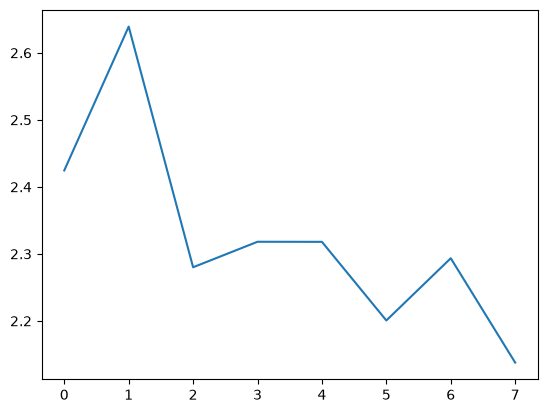

In [37]:
plt.plot(lossi)

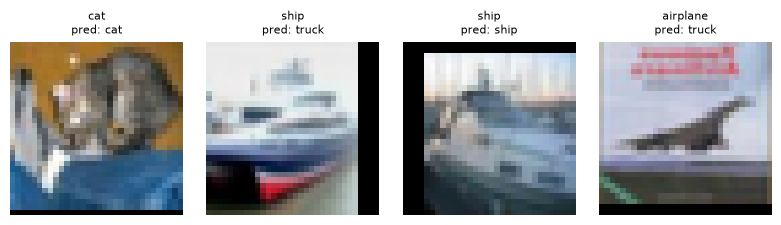

In [46]:
mean_t = torch.tensor(mean).view(3, 1, 1)
std_t  = torch.tensor(std).view(3, 1, 1)
classes = train_ds.features["label"].names

def show(img, label):
    img = (img * std_t + mean_t).clamp(0, 1)      # undo Normalize
    plt.imshow(img.permute(1, 2, 0))          # (3,32,32) -> (32,32,3)
    plt.title(classes[label])
    plt.axis("off")

x, y = next(iter(val_dl))

with torch.no_grad():
    preds = mymodel(x).argmax(1).cpu()

plt.figure(figsize=(8, 8))
for i in range(4):
    plt.subplot(4, 4, i + 1)
    show(x[i], y[i].item())
    plt.title(f"{classes[y[i]]}\npred: {classes[preds[i]]}", fontsize=8)
plt.tight_layout(); plt.show()

In [48]:
@torch.no_grad()
def get_loss_one_batch(split):
	dl = {
		"train": train_dl,
		"val": val_dl
	}[split]

	ctx, target = next(iter(dl))
	logits = mymodel(ctx)
	loss = criterion(logits, target)

	print(split, loss.item())

get_loss_one_batch("train")
get_loss_one_batch("val")

train 2.0207912921905518
val 2.092810869216919
